In [1]:
using JARS


sa_file = JIO.load_file(joinpath(homedir(), "testdata_JARS","sa_raw_data.h5"))

t = sa_file["integration_info"]["save_tax"]

x = JIO.collect_over_frames("x",sa_file,type=1, step=10)

y = JIO.collect_over_frames("y",sa_file,type=1, step=10)

z = JIO.collect_over_frames("z",sa_file,type=1, step=10)

msd = JOB.MSD(t,x, y, z=z)

[ Info: Precompiling JARS [463ed9ea-d574-4d46-b957-79042c805606] (caches not reused: 1 for different Julia build configuration, 1 for file size changed)
Precompiling packages...
   4.3 s  ✓ JARS
  1 dependency successfully precompiled in 5 seconds. 347 already precompiled.
┌ Warning: File likely not written by JLD2. Skipping header verification.
└ @ JLD2 ~/.julia/packages/JLD2/rm5a0/src/file_header.jl:21


Dict{String, Vector{Float64}} with 2 entries:
  "lagtime" => [0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8  …  998.2, 998…
  "msd"     => [0.0, 0.00026962, 0.00107138, 0.00238645, 0.00418702, 0.00643887…

In [2]:
using CairoMakie

set_theme!(sans_serif_theme())

function plot_msd!(pos)
    ax = Axis(pos, xscale=log10, yscale=log10, xlabel="lagtime", ylabel=L"\langle r2 \rangle^2")

    ylims!(ax, high=1e0, low=1e-5)

    scatterlines!(ax, msd["lagtime"], msd["msd"])
end
function plot_msd_zoom!(pos)
    ax = Axis(pos, xscale=log10, yscale=log10, xlabel="lagtime", ylabel=L"\langle r2 \rangle^2")

    ylims!(ax, high=1e0, low=1e-2)

    xlims!(ax, low=10^(1.5))

    scatterlines!(ax, msd["lagtime"], msd["msd"])
end



plot_msd_zoom! (generic function with 1 method)

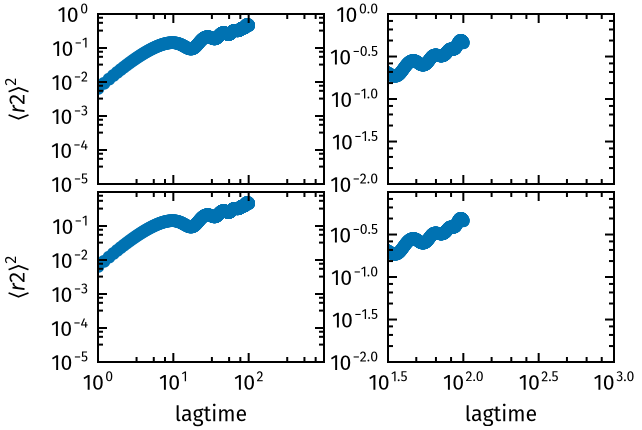

CairoMakie.Screen{IMAGE}


In [3]:
f = Figure1col()

plot_msd!(f[1,1])
plot_msd_zoom!(f[1,2])
plot_msd!(f[2,1])
plot_msd_zoom!(f[2,2])

# plot_msd!(f[1,3])
# plot_msd!(f[2,3])

compress_whitespace!(f,sharex=true, sharey=false, shareylabel=true)
save(joinpath(pwd(),"msd_1col.pdf"), f; backend = CairoMakie)
display(f)

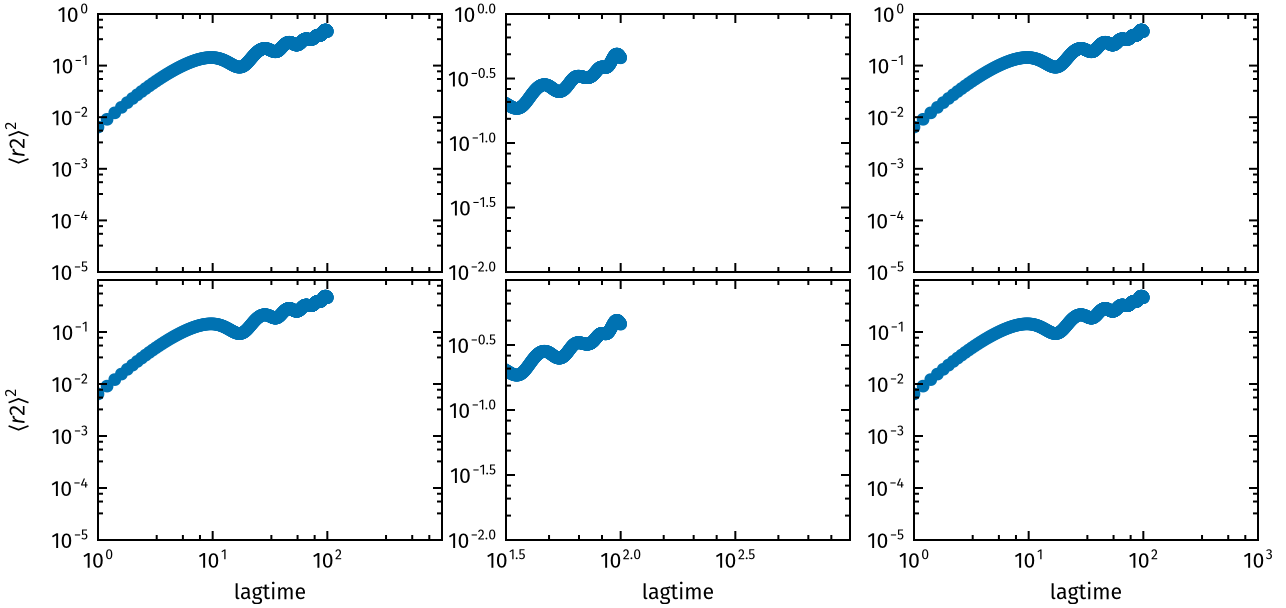

CairoMakie.Screen{IMAGE}


In [4]:
f = Figure2col()

plot_msd!(f[1,1])
plot_msd_zoom!(f[1,2])
plot_msd!(f[2,1])
plot_msd_zoom!(f[2,2])

plot_msd!(f[1,3])
plot_msd!(f[2,3])

compress_whitespace!(f,sharex=true, sharey=false, shareylabel=true)
save(joinpath(pwd(),"msd_2col.pdf"), f; backend = CairoMakie)
display(f)

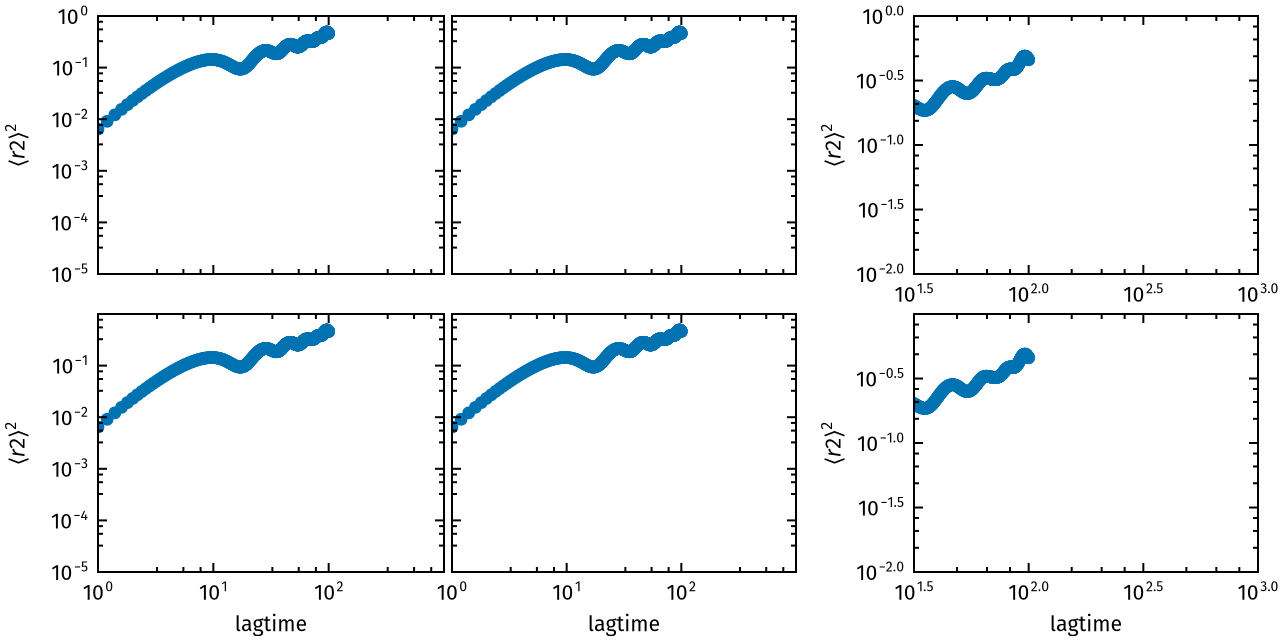

In [ ]:
f = Figure2col()
a = plot_msd!(f[1, 1]);  b = plot_msd!(f[1, 2]);  c = plot_msd_zoom!(f[1, 3])
d = plot_msd!(f[2, 1]);  e = plot_msd!(f[2, 2]);  g = plot_msd_zoom!(f[2, 3])

share!(f; x = true, y = true, cells = (1:2, 1:2))  
share!(f; x=true, cells = (1:2, 3))        
compress_whitespace!(f)

colgap!(f.layout, 2, 12)     
adjust_height!(f)